# Bài 4 — Phân tích chỉ số hạnh phúc các quốc gia

**Dataset:** [World Happiness Report trên Kaggle](https://www.kaggle.com/datasets/unsdsn/world-happiness/data)

Cần một tệp .csv có sẵn để chạy. Tải một trong 2 tệp 2015 hoặc 2016 để đầy đủ dữ liệu nhất. (Các năm sau bị đổi tên cột và một số không sẵn Region)


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

Saving 2015.csv to 2015.csv


## 1. So sánh điểm hạnh phúc giữa các quốc gia và khu vực

In [4]:
# Chuẩn hóa tên cột để đọc được định dạng của các năm khác nhau
import re

def clean_name(name):
    return re.sub(r'[^a-z0-9]', '', str(name).lower())

col_map = {clean_name(c): c for c in df.columns}
def get_col(*names):
    for name in names:
        key = clean_name(name)
        if key in col_map:
            return col_map[key]
    return None

rename = {
    get_col('Country', 'Country or region'): 'Country',
    get_col('Region', 'Regional indicator'): 'Region',
    get_col('Happiness Score', 'Score', 'Ladder score'): 'Happiness Score',
    get_col('Economy (GDP per Capita)', 'GDP per capita'): 'GDP',
    get_col('Family', 'Social support'): 'Social support',
    get_col('Health (Life Expectancy)', 'Healthy life expectancy'): 'Life expectancy'
}
rename = {old: new for old, new in rename.items() if old is not None}
df = df.rename(columns=rename)

required = ['Country', 'Region', 'Happiness Score', 'GDP', 'Social support', 'Life expectancy']
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f'Thiếu cột {missing_cols}. Hãy dùng file 2015.csv hoặc 2016.csv có Region.')

for col in ['Happiness Score', 'GDP', 'Social support', 'Life expectancy']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=required).copy()

print('Top 10 quốc gia có điểm hạnh phúc cao:')
display(df.nlargest(10, 'Happiness Score')[['Country', 'Region', 'Happiness Score']])

print('Điểm hạnh phúc trung bình theo khu vực:')
display(df.groupby('Region')['Happiness Score'].mean().sort_values(ascending=False).to_frame('Điểm trung bình'))

Top 10 quốc gia có điểm hạnh phúc cao:


,Country,Region,Happiness Score
0,Switzerland,Western Europe,7.587
1,Iceland,Western Europe,7.561
2,Denmark,Western Europe,7.527
3,Norway,Western Europe,7.522
4,Canada,North America,7.427
5,Finland,Western Europe,7.406
6,Netherlands,Western Europe,7.378
7,Sweden,Western Europe,7.364
8,New Zealand,Australia and New Zealand,7.286
9,Australia,Australia and New Zealand,7.284


Điểm hạnh phúc trung bình theo khu vực:


,Điểm trung bình
Region,
Australia and New Zealand,7.285000
North America,7.273000
Western Europe,6.689619
Latin America and Caribbean,6.144682
Eastern Asia,5.626167
Middle East and Northern Africa,5.406900
Central and Eastern Europe,5.332931
Southeastern Asia,5.317444
Southern Asia,4.580857


## 2. Tính trung bình, trung vị, phương sai và độ lệch chuẩn bằng NumPy

In [5]:
score = df['Happiness Score'].to_numpy()
print('Trung bình:', np.mean(score))
print('Trung vị:', np.median(score))
print('Phương sai:', np.var(score))
print('Độ lệch chuẩn:', np.std(score))

Trung bình: 5.375734177215189
Trung vị: 5.2325
Phương sai: 1.3027504356673612
Độ lệch chuẩn: 1.1413809336358134


## 3. Xếp hạng các quốc gia bằng Pandas

In [6]:
df['Rank'] = df['Happiness Score'].rank(method='min', ascending=False).astype(int)
ranking = df.sort_values(['Rank', 'Country'])[['Rank', 'Country', 'Region', 'Happiness Score']]
display(ranking.head(10))

,Rank,Country,Region,Happiness Score
0,1,Switzerland,Western Europe,7.587
1,2,Iceland,Western Europe,7.561
2,3,Denmark,Western Europe,7.527
3,4,Norway,Western Europe,7.522
4,5,Canada,North America,7.427
5,6,Finland,Western Europe,7.406
6,7,Netherlands,Western Europe,7.378
7,8,Sweden,Western Europe,7.364
8,9,New Zealand,Australia and New Zealand,7.286
9,10,Australia,Australia and New Zealand,7.284


## 4. Phân tích tương quan giữa hạnh phúc, GDP, hỗ trợ xã hội và tuổi thọ

In [7]:
corr_cols = ['Happiness Score', 'GDP', 'Social support', 'Life expectancy']
corr = df[corr_cols].corr()
display(corr)

,Happiness Score,GDP,Social support,Life expectancy
Happiness Score,1.000000,0.780966,0.740605,0.724200
GDP,0.780966,1.000000,0.645299,0.816478
Social support,0.740605,0.645299,1.000000,0.531104
Life expectancy,0.724200,0.816478,0.531104,1.000000


## 5. Vẽ heatmap, scatterplot và biểu đồ xếp hạng

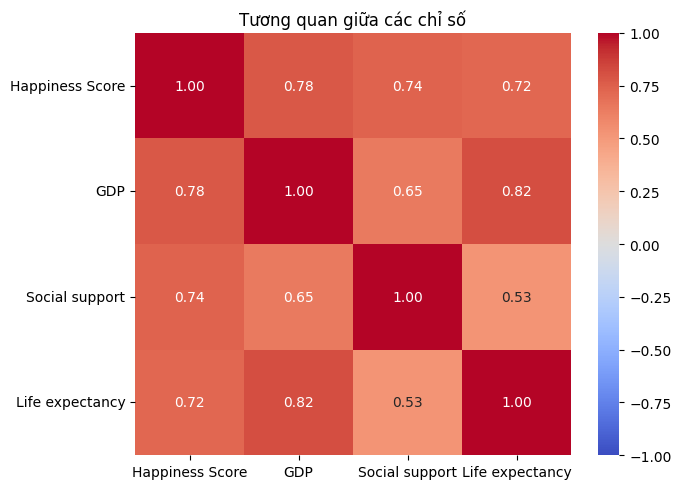

In [8]:
# Heatmap tương quan
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Tương quan giữa các chỉ số')
plt.tight_layout()
plt.show()

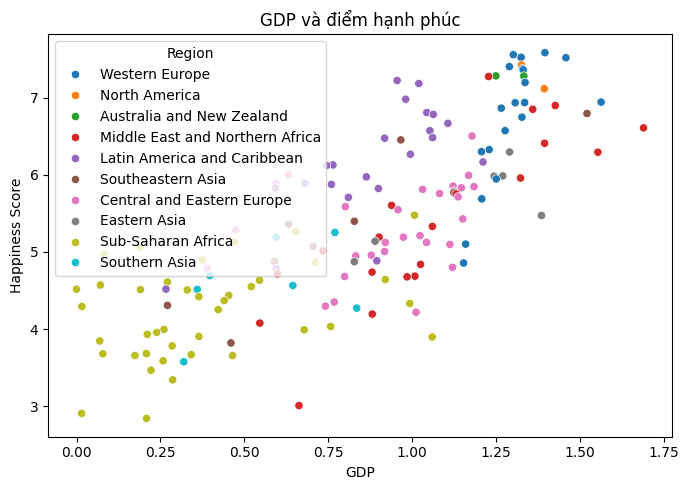

In [9]:
# Scatterplot: GDP và điểm hạnh phúc
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='GDP', y='Happiness Score', hue='Region')
plt.title('GDP và điểm hạnh phúc')
plt.tight_layout()
plt.show()

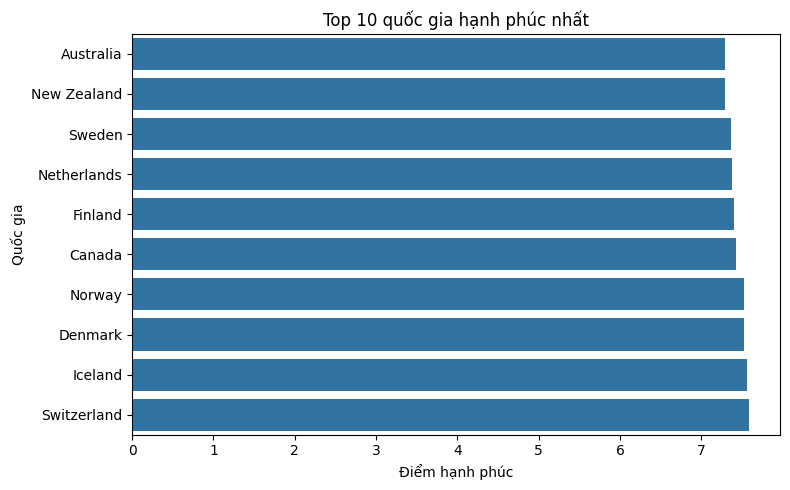

In [10]:
# Biểu đồ xếp hạng 10 quốc gia có điểm cao nhất
top10 = df.nlargest(10, 'Happiness Score').sort_values('Happiness Score')
plt.figure(figsize=(8, 5))
sns.barplot(data=top10, x='Happiness Score', y='Country')
plt.title('Top 10 quốc gia hạnh phúc nhất')
plt.xlabel('Điểm hạnh phúc')
plt.ylabel('Quốc gia')
plt.tight_layout()
plt.show()